# Pipeline-ul de date, pas cu pas

Acest notebook arată **cu imagini reale** ce face codul din `src/traffic_signs/` (milestone-urile M1–M3).
Rulează celulele în ordine, de sus în jos (Shift+Enter). Nu antrenăm nimic aici; doar pregătim datele.

Traseul unei imagini:

```
CSV → tabel → împărțire train/val (pe track-uri) → încărcare → decupare ROI → 48×48 → valori 0..1 → augmentare → batch-uri de 64
```

## 0. Pregătire
Importăm modulele proiectului și fixăm **seed-ul** (42), ca orice „aleator” să dea același rezultat la fiecare rulare.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from traffic_signs import config
from traffic_signs.classes import class_name
from traffic_signs.dataset import load_train_index
from traffic_signs.split import load_split
from traffic_signs.preprocessing import load_image, crop_roi, preprocess, prepare
from traffic_signs.augmentation import build_augmentation, compute_class_weights
from traffic_signs.pipeline import make_dataset
from traffic_signs.reproducibility import set_global_seed

set_global_seed(config.SEED)
print("Date în:", config.DATA_DIR)
print("Clase:", config.NUM_CLASSES, "| mărime imagine CNN:", config.IMG_SIZE_CNN, "| batch:", config.BATCH_SIZE)

Date în: /Users/ionutgalan/Projects/University_Projects/Tehnici_Inteligenta_Artificiala/archive
Clase: 43 | mărime imagine CNN: 48 | batch: 64


## 1. Tabelul cu imagini (`dataset.py`)
`load_train_index` citește `archive/Train.csv` și întoarce un **tabel** (DataFrame): un rând = o imagine.

- `path` – unde e fișierul
- `class_id` – ce semn este (0…42)
- `track_id` – din ce „filmare” face parte (vezi pasul 2)
- `width`, `height` – dimensiunea imaginii
- `roi_x1 … roi_y2` – dreptunghiul în care e semnul (ROI = *region of interest*)

In [2]:
df = load_train_index(config.DATA_DIR)
print(len(df), "imagini de antrenare")
df.head()

39209 imagini de antrenare


,path,class_id,track_id,width,height,roi_x1,roi_y1,roi_x2,roi_y2
0,/Users/ionutgalan/Projects/University_Projects...,20,00020_00000,27,26,5,5,22,20
1,/Users/ionutgalan/Projects/University_Projects...,20,00020_00000,28,27,5,6,23,22
2,/Users/ionutgalan/Projects/University_Projects...,20,00020_00000,29,26,6,5,24,21
3,/Users/ionutgalan/Projects/University_Projects...,20,00020_00000,28,27,5,6,23,22
4,/Users/ionutgalan/Projects/University_Projects...,20,00020_00000,28,26,5,5,23,21


## 2. Ce este un *track* și de ce contează
Fiecare semn fizic a fost filmat de **30 de ori** în timp ce mașina se apropia. Cele 30 de poze formează un *track*.
Sunt aproape identice — de aceea **nu** avem voie să punem unele în train și altele în validare (validarea ar „copia” din train).

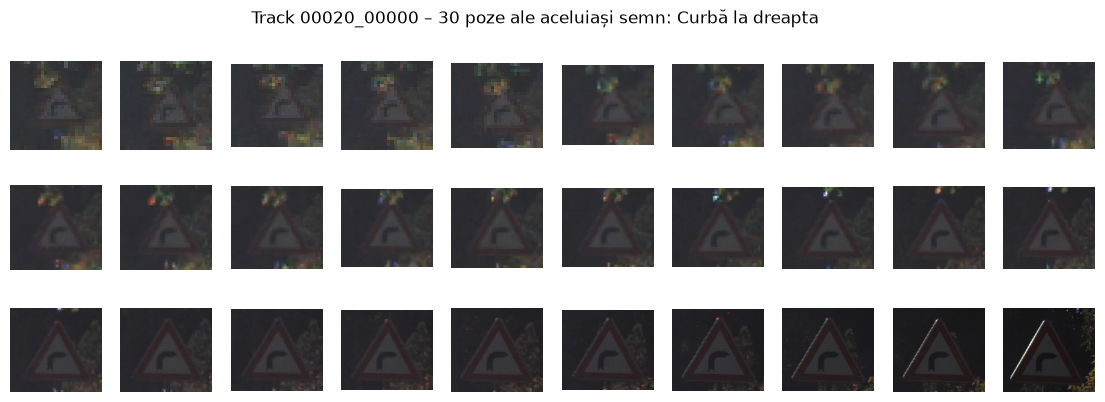

Număr total de track-uri: 1307


In [3]:
track = df["track_id"].iloc[0]
frames = df[df["track_id"] == track]
fig, axes = plt.subplots(3, 10, figsize=(14, 4.5))
for ax, p in zip(axes.flat, frames["path"]):
    ax.imshow(load_image(p)); ax.axis("off")
fig.suptitle(f"Track {track} – {len(frames)} poze ale aceluiași semn: {class_name(int(frames['class_id'].iloc[0]))}")
plt.show()
print("Număr total de track-uri:", df["track_id"].nunique())

## 3. O singură imagine, pas cu pas (`preprocessing.py`)
### 3a. `load_image` – încărcare
Întoarce un tablou de numere de forma **(înălțime, lățime, 3)**: 3 canale de culoare (roșu, verde, albastru), fiecare cu valori 0–255.

Semn: Stop
Formă: (63, 63, 3) | tip: uint8 | min/max: 54 255


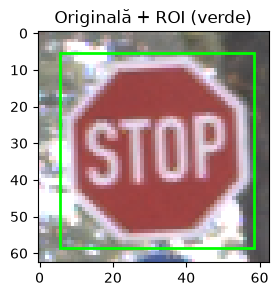

In [4]:
row = df.loc[22632]  # un semn „Stop” bine luminat
img = load_image(row["path"])
print("Semn:", class_name(int(row["class_id"])))
print("Formă:", img.shape, "| tip:", img.dtype, "| min/max:", img.min(), img.max())

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(img)
x1, y1, x2, y2 = row[["roi_x1", "roi_y1", "roi_x2", "roi_y2"]].astype(int)
ax.add_patch(patches.Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1 + 1, y2 - y1 + 1, fill=False, color="lime", lw=2))
ax.set_title("Originală + ROI (verde)")
plt.show()

### 3b. `crop_roi` – decupare
Păstrăm doar dreptunghiul verde. Dacă coordonatele ies din imagine, funcția le limitează (nu dă eroare).

In [5]:
cropped = crop_roi(img, x1, y1, x2, y2)
print("Înainte:", img.shape, "→ după decupare:", cropped.shape)

Înainte: (63, 63, 3) → după decupare: (53, 53, 3)


### 3c. `preprocess` – redimensionare + normalizare
Modelul vrea **toate imaginile de aceeași mărime** (48×48) și valori **între 0 și 1** (împărțim la 255).
Valorile mici și uniforme ajută antrenarea să fie stabilă.

Formă: (48, 48, 3) | tip: float32 | min/max: 0.243 1.0


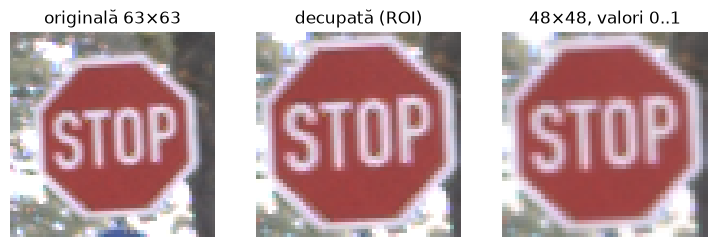

In [6]:
small = preprocess(cropped, config.IMG_SIZE_CNN)
print("Formă:", small.shape, "| tip:", small.dtype, "| min/max:", round(float(small.min()), 3), round(float(small.max()), 3))

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (im, t) in zip(axes, [(img, f"originală {img.shape[1]}×{img.shape[0]}"),
                               (cropped, "decupată (ROI)"),
                               (small, "48×48, valori 0..1")]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.show()

### 3d. `prepare` – toți pașii într-un singur apel
Aceasta e funcția pe care o folosesc **și antrenarea, și aplicația web (M6)**. Așa ne asigurăm că modelul vede
imaginile pregătite **exact la fel** la antrenare și în aplicație.

In [7]:
same = prepare(row["path"], config.IMG_SIZE_CNN, roi=(x1, y1, x2, y2))
print("prepare() dă același rezultat ca pașii de mai sus:", np.allclose(same, small))

prepare() dă același rezultat ca pașii de mai sus: True


## 4. Augmentarea (`augmentation.py`)
La antrenare, modelul vede imaginile **ușor modificate** (rotite ±15°, mărite, deplasate, mai luminoase/întunecate).
Așa învață *semnul*, nu *poza exactă*, și tocește mai puțin (overfitting).

**Nu oglindim**: un „viraj la stânga” oglindit ar deveni „viraj la dreapta”.

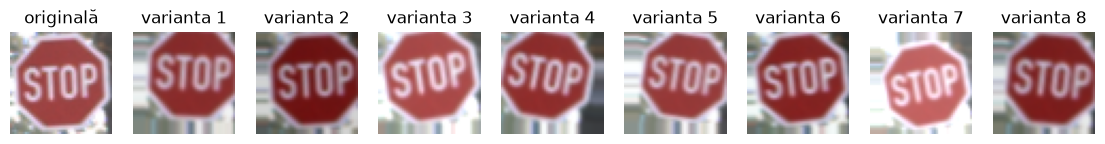

Straturi: ['RandomRotation', 'RandomZoom', 'RandomTranslation', 'RandomBrightness', 'RandomContrast', 'ClipToUnitRange']


In [8]:
augment = build_augmentation(config.SEED)
batch = np.repeat(small[None], 8, axis=0)            # aceeași imagine de 8 ori
augmented = augment(batch, training=True).numpy()

fig, axes = plt.subplots(1, 9, figsize=(14, 2.2))
axes[0].imshow(small); axes[0].set_title("originală")
for i, ax in enumerate(axes[1:]):
    ax.imshow(augmented[i]); ax.set_title(f"varianta {i + 1}")
for ax in axes: ax.axis("off")
plt.show()
print("Straturi:", [layer.__class__.__name__ for layer in augment.layers])

### 4b. Atenție: imaginile întunecate
Multe poze din GTSRB sunt filmate seara sau în umbră (cam **o treime** au luminozitatea medie sub 60 din 255).
`RandomBrightness(0.2)` adaugă sau scade **până la 0,2** din toată scala 0..1. Pe o imagine care are deja
valori doar până la ~0,2, scăderea o poate face **complet neagră**, adică modelul ar primi o imagine fără niciun semn.

Valoare maximă în imaginea originală: 0.235


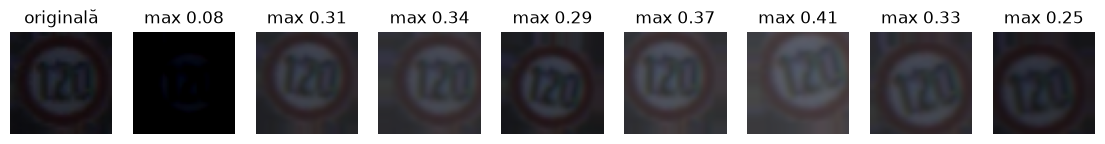

Imagini întunecate (medie < 60/255) într-un eșantion de 2000: 36%


In [9]:
dark_row = df.iloc[12345]
dark = prepare(dark_row["path"], config.IMG_SIZE_CNN,
               roi=tuple(dark_row[["roi_x1", "roi_y1", "roi_x2", "roi_y2"]].astype(int)))
dark_aug = augment(np.repeat(dark[None], 8, axis=0), training=True).numpy()
print("Valoare maximă în imaginea originală:", round(float(dark.max()), 3))

fig, axes = plt.subplots(1, 9, figsize=(14, 2.2))
axes[0].imshow(dark); axes[0].set_title("originală")
for i, ax in enumerate(axes[1:]):
    ax.imshow(dark_aug[i]); ax.set_title(f"max {dark_aug[i].max():.2f}")
for ax in axes: ax.axis("off")
plt.show()

sample_paths = df["path"].sample(2000, random_state=config.SEED)
share_dark = np.mean([load_image(p).mean() < 60 for p in sample_paths])
print(f"Imagini întunecate (medie < 60/255) într-un eșantion de 2000: {share_dark:.0%}")

**Ce facem cu asta (decizie pentru M4):** micșorăm intervalul de luminozitate (ex. 0,1) sau folosim o variație
*proporțională* în loc de una absolută, apoi comparăm pe validare. E exact genul de observație care merită pusă
în prezentare: arată că am verificat datele, nu doar am rulat codul.

## 5. Împărțirea train / validare (`split.py`)
Împărțirea a fost făcută o singură dată (`scripts/make_split.py`) și salvată în `splits/train_val_split.csv`.
Pentru fiecare clasă, ~15% din **track-uri** merg în validare.

In [10]:
train_df, val_df = load_split(config.SPLITS_DIR / "train_val_split.csv", config.DATA_DIR)
common = set(train_df["track_id"]) & set(val_df["track_id"])
print(f"Train: {len(train_df)} imagini, {train_df['track_id'].nunique()} track-uri")
print(f"Val:   {len(val_df)} imagini, {val_df['track_id'].nunique()} track-uri ({len(val_df) / (len(train_df) + len(val_df)):.1%})")
print("Track-uri comune între train și val:", len(common))
print("Clase prezente în val:", val_df["class_id"].nunique(), "din", config.NUM_CLASSES)

Train: 33359 imagini, 1112 track-uri
Val:   5850 imagini, 195 track-uri (14.9%)
Track-uri comune între train și val: 0
Clase prezente în val: 43 din 43


## 6. Clase dezechilibrate → ponderi (`compute_class_weights`)
Unele semne au de ~10 ori mai multe imagini decât altele. Fără ponderi, modelul ar „ignora” clasele rare.
Ponderea unei clase rare e **mare** (greșelile pe ea „costă” mai mult), a unei clase frecvente e **mică**.

In [11]:
weights = compute_class_weights(train_df["class_id"])
counts = train_df["class_id"].value_counts()
for c in [int(counts.idxmin()), int(counts.idxmax())]:
    print(f"Clasa {c:2d} ({class_name(c)}): {counts[c]:5d} imagini → pondere {weights[c]:.2f}")

Clasa  0 (Limită de viteză 20 km/h):   180 imagini → pondere 4.31
Clasa  2 (Limită de viteză 50 km/h):  1920 imagini → pondere 0.40


## 7. Totul împreună: `make_dataset` (`pipeline.py`)
Funcția leagă pașii de mai sus într-un flux TensorFlow care dă **batch-uri**: 64 de imagini + 64 de etichete.

Eticheta e în format **one-hot**: un vector de 43 de numere, toate 0, cu un singur **1** pe poziția clasei corecte.
(Aici folosim doar 64 de imagini din train, ca să ruleze repede.)

Imagini: (16, 48, 48, 3) <dtype: 'float32'> | Etichete: (16, 43)
Prima etichetă (one-hot): [0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0]
Poziția lui 1 = 9 → Depășirea interzisă


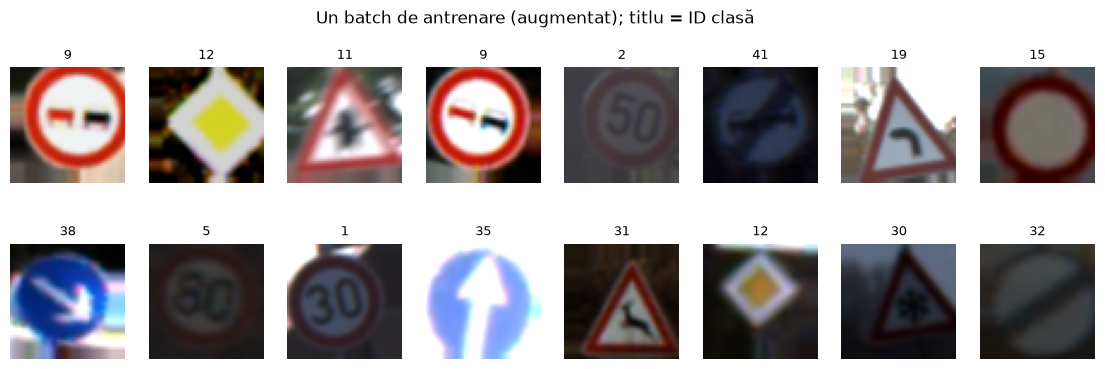

In [12]:
sample = train_df.sample(64, random_state=config.SEED).reset_index(drop=True)
ds = make_dataset(sample, image_size=config.IMG_SIZE_CNN, batch_size=16, training=True)
images, labels = next(iter(ds))
print("Imagini:", images.shape, images.dtype, "| Etichete:", labels.shape)
print("Prima etichetă (one-hot):", labels[0].numpy().astype(int))
print("Poziția lui 1 =", int(np.argmax(labels[0])), "→", class_name(int(np.argmax(labels[0]))))

fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax, im, lab in zip(axes.flat, images.numpy(), labels.numpy()):
    ax.imshow(im); ax.set_title(str(int(np.argmax(lab))), fontsize=9); ax.axis("off")
fig.suptitle("Un batch de antrenare (augmentat); titlu = ID clasă")
plt.show()

## Rezumat
| Pas | Funcție | Rezultat |
|---|---|---|
| Citire | `load_train_index` | tabel cu 39.209 imagini |
| Împărțire | `split_by_track` / `load_split` | train 33.359 / val 5.850, fără track-uri comune |
| Pregătire imagine | `prepare` | 48×48×3, valori 0..1 |
| Variații | `build_augmentation` | rotire, zoom, deplasare, lumină, contrast — fără oglindire |
| Dezechilibru | `compute_class_weights` | clasele rare cântăresc mai mult |
| Flux final | `make_dataset` | batch-uri (imagini, etichete one-hot) |

**Următorul pas (M4):** construim CNN-ul nostru și îl antrenăm pe `make_dataset(train_df, 48, training=True)`,
verificând pe `make_dataset(val_df, 48)`.